In [1]:
import deeplabcut, shutil
import pandas as pd
from pathlib import Path
from deeplabcut.utils import auxiliaryfunctions

DATA = Path(r".\data")
PROJECT = next(Path(r".\dlc").glob("pupil-dani-*"))
config_path = str(PROJECT / "config.yaml")
SESSIONS = [
    "094124",
    "110535",
    "115300",
    "131707",
    "135059",
    "171101",
    "172731",
    "214411",
]
TEST_SESSION = "110535"
print(config_path)

dlc\pupil-dani-2026-11-13\config.yaml


In [2]:
def configure_project(config_path, sessions, frame_size=(1280, 1024)):
    cfg = auxiliaryfunctions.read_config(config_path)
    w, h = frame_size
    proj = cfg["project_path"]
    cfg["bodyparts"] = [
        "eye-anterior",
        "eye-posterior",
        "eye-dorsal",
        "eye-ventral",
        "pupil-anterior",
        "pupil-posterior",
        "pupil-dorsal",
        "pupil-ventral",
    ]
    cfg["video_sets"] = {
        f"{proj}/videos/{s}.mp4": {"crop": f"0, {w}, 0, {h}"} for s in sessions
    }
    cfg["pcutoff"] = 0.6
    cfg["default_net_type"] = "resnet_50"
    cfg["TrainingFraction"] = [0.9]
    auxiliaryfunctions.write_config(config_path, cfg)

configure_project(config_path, SESSIONS)

In [3]:
def copy_labeled_data(src_root, config_path, sessions):
    proj = Path(auxiliaryfunctions.read_config(config_path)["project_path"])
    for s in sessions:
        src, dst = Path(src_root) / "labeled-data" / s, proj / "labeled-data" / s
        dst.mkdir(parents=True, exist_ok=True)
        for f in src.iterdir():
            shutil.copy2(f, dst / f.name)


copy_labeled_data(DATA, config_path, SESSIONS)

In [4]:
deeplabcut.create_training_dataset(config_path)


def merged_counts(config_path):
    cfg = auxiliaryfunctions.read_config(config_path)
    folder = Path(cfg["project_path"]) / auxiliaryfunctions.get_training_set_folder(cfg)
    df = pd.read_hdf(next(folder.glob("CollectedData_*.h5")))
    counts = pd.Series([i[1] for i in df.index]).value_counts().sort_index()
    print(counts.to_string())
    print("total frames:", len(df))
    return df


df = merged_counts(config_path)

094124    40
110535    39
115300    34
131707    60
135059    40
171101    20
172731    80
214411    80
total frames: 393


In [5]:
def split_by_session(config_path, test_session):
    cfg = auxiliaryfunctions.read_config(config_path)
    folder = Path(cfg["project_path"]) / auxiliaryfunctions.get_training_set_folder(cfg)
    df = pd.read_hdf(next(folder.glob("CollectedData_*.h5")))
    test = [i for i, idx in enumerate(df.index) if idx[1] == test_session]
    train = [i for i, idx in enumerate(df.index) if idx[1] != test_session]
    return train, test


train_inds, test_inds = split_by_session(config_path, TEST_SESSION)
print(f"train frames: {len(train_inds)} | test frames: {len(test_inds)}")

deeplabcut.create_training_dataset(
    config_path,
    Shuffles=[1],
    trainIndices=[train_inds],
    testIndices=[test_inds],
    net_type="resnet_50",
)

train frames: 354 | test frames: 39


ValueError: Cannot create shuffle 1 as it already exists - you must either create the dataset with `userfeedback=False` or delete the shuffle with index 1 manually (in `dlc-models`/`dlc-models-pytorch` and in the `training-datasets` folder) if you want to create a new shuffle with that index. You can otherwise create a shuffle with a new index. Existing indices are [1, 99, 100, 101, 102].

In [6]:
deeplabcut.train_network(
    config_path, shuffle=1, saveiters=5000, displayiters=500, maxiters=50000
)

C:\Users\edoua\AppData\Local\Temp\ipykernel_15476\3500036660.py:1: DLCDeprecationWarning: Parameter 'maxiters' of train_network is deprecated since 3.0.0; use 'max_iters' instead.
  deeplabcut.train_network(
Training with configuration:
config_version: 0
model: backbone={'type': 'ResNet', 'model_name': 'resnet50_gn', 'output_stride': 16, 'freeze_bn_stats': False, 'freeze_bn_weights': False} heads={'bodypart': {'type': 'HeatmapHead', 'weight_init': 'normal', 'predictor': {'type': 'HeatmapPredictor', 'apply_sigmoid': False, 'clip_scores': True, 'location_refinement': True, 'locref_std': 7.2801}, 'target_generator': {'type': 'HeatmapGaussianGenerator', 'num_heatmaps': 8, 'pos_dist_thresh': 17, 'heatmap_mode': 'KEYPOINT', 'gradient_masking': False, 'generate_locref': True, 'locref_std': 7.2801}, 'criterion': {'heatmap': {'type': 'WeightedMSECriterion', 'weight': 1.0}, 'locref': {'type': 'WeightedHuberCriterion', 'weight': 0.05}}, 'heatmap_config': {'channels': [2048, 8], 'kernel_size': [3]

In [7]:
deeplabcut.evaluate_network(
    config_path,
    Shuffles=[1],
    plotting=True,
    per_keypoint_evaluation=True,
    snapshots_to_evaluate=["snapshot-200"],
)

Evaluation scorer: DLC_Resnet50_pupilNov13shuffle1_snapshot_200


100%|██████████| 39/39 [00:01<00:00, 22.39it/s]


Evaluation results file: DLC_Resnet50_pupilNov13shuffle1_snapshot_200-results.csv
Evaluation results for DLC_Resnet50_pupilNov13shuffle1_snapshot_200-results.csv (pcutoff: 0.6):
train rmse              2.41
train rmse_pcutoff      2.41
train mAP              98.69
train mAR              99.35
test rmse             238.41
test rmse_pcutoff        NaN
test mAP                4.58
test mAR                5.64
Name: (0.9, 1, 200, -1, 0.6), dtype: float64
Per-bodypart evaluation results (DLC_Resnet50_pupilNov13shuffle1_snapshot_200-keypoint-results):
  Train error (px)
    eye-anterior:      2.88px
    eye-posterior:     2.50px
    eye-dorsal:        2.86px
    eye-ventral:       2.82px
    pupil-anterior:    2.05px
    pupil-posterior:   2.31px
    pupil-dorsal:      1.99px
    pupil-ventral:     1.86px
  Test error (px)
    eye-anterior:      360.41px
    eye-posterior:     204.49px
    eye-dorsal:        178.27px
    eye-ventral:       305.48px
    pupil-anterior:    211.13px
    pupil-p

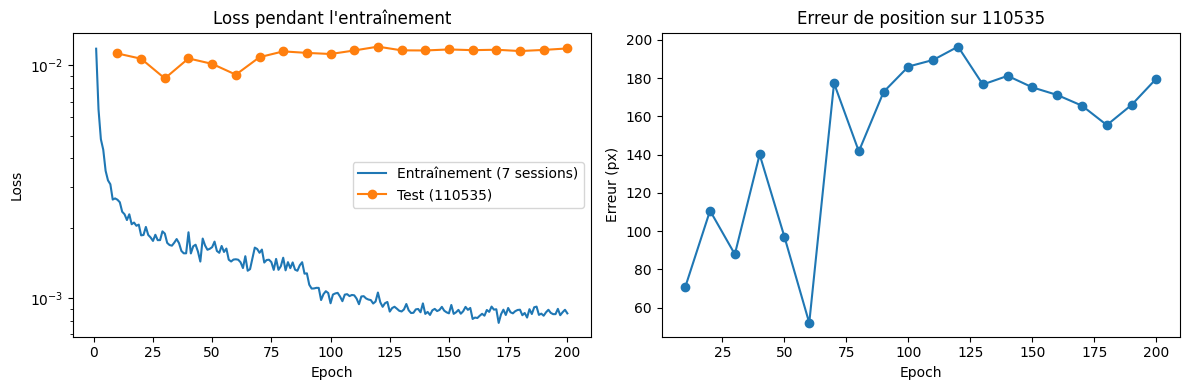

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

train_dir = PROJECT / "dlc-models-pytorch/iteration-0/pupilNov13-trainset90shuffle1/train"
stats = pd.read_csv(train_dir / "learning_stats.csv").tail(200)   # les 200 epochs du vrai entraînement
evals = stats.dropna(subset=["metrics/test.rmse"])                # le test est mesuré toutes les 10 epochs

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(stats["step"], stats["losses/train.total_loss"], label="Entraînement (7 sessions)")
ax1.plot(evals["step"], evals["losses/eval.total_loss"], marker="o", label="Test (110535)")
ax1.set_yscale("log")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_title("Loss pendant l'entraînement")
ax1.legend()

ax2.plot(evals["step"], evals["metrics/test.rmse"], marker="o")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Erreur (px)")
ax2.set_title("Erreur de position sur 110535")

plt.tight_layout()
plt.show()